In [1]:
# ===== STEP 1: Problem definition + metrics =====
import numpy as np, random
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# ---- Project config (idha mattum inga maathunga, matha steps-la idha use pannuvom) ----
CONFIG = {
    "seed": 42,
    "target": "Time_taken(min)",
    "use_pickup": True,        # True = Kaggle score version, False = real-time ETA version
    "test_size": 0.15,
    "cv_folds": 5,
    "tolerance_min": 5,        # "within +-5 min" success metric
    "late_penalty": 2.0,       # late-a sonnadhu (under-predict) cost, early-a sonnadhu vida 2x mosam
    "target_r2_range": (0.80, 0.85),   # realistic expected range, guarantee illa
    "leakage_alarm_r2": 0.95,  # idhukku mela vandha leakage nu suspect pannanum
}

# ---- Reproducibility ----
random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])

# ---- Metric functions (ella steps-layum idhe use pannuvom) ----
def mae(y, p):  return mean_absolute_error(y, p)
def rmse(y, p): return float(np.sqrt(mean_squared_error(y, p)))
def r2(y, p):   return r2_score(y, p)

def within_tol(y, p, tol=CONFIG["tolerance_min"]):
    """Evlo % orders-la prediction +-tol minutes-kulla irukku"""
    return float(np.mean(np.abs(np.asarray(y) - np.asarray(p)) <= tol) * 100)

def asym_cost(y, p, late_penalty=CONFIG["late_penalty"]):
    """Under-predict (customer-ku late) ku adhiga penalty. Kuraivu = nalladhu."""
    err = np.asarray(y) - np.asarray(p)          # +ve = actual adhigam = late aachu
    return float(np.mean(np.where(err > 0, late_penalty * err, -err)))

def leakage_check(y, p):
    score = r2(y, p)
    if score > CONFIG["leakage_alarm_r2"]:
        print(f"WARNING: R2={score:.3f} romba adhigam. Leakage irukkalaam, features check pannunga.")
    return score

def report(name, y, p):
    print(f"{name:24s} MAE={mae(y,p):6.3f} | RMSE={rmse(y,p):6.3f} | R2={r2(y,p):.4f} "
          f"| within+-{CONFIG['tolerance_min']}min={within_tol(y,p):5.1f}% | cost={asym_cost(y,p):6.3f}")

# ---- Self-test: dummy numbers-la functions work aagudha nu paakkalaam ----
y_true = np.array([30, 25, 40, 35, 20])
y_pred = np.array([28, 27, 33, 36, 20])
report("Self-test", y_true, y_pred)

print("\nPROJECT RULES")
print("1. Primary metric: MAE (minutes)")
print("2. Test set oru dhadava mattum touch pannuvom")
print("3. Ella encoder/imputer train data-la mattum fit")
print(f"4. Realistic target R2: {CONFIG['target_r2_range']}")
print(f"5. R2 > {CONFIG['leakage_alarm_r2']} vandha leakage investigate pannanum")
print(f"6. Version: {'Kaggle (pickup time serthu)' if CONFIG['use_pickup'] else 'Real-time (pickup time illama)'}")

Self-test                MAE= 2.400 | RMSE= 3.406 | R2=0.7680 | within+-5min= 80.0% | cost= 4.200

PROJECT RULES
1. Primary metric: MAE (minutes)
2. Test set oru dhadava mattum touch pannuvom
3. Ella encoder/imputer train data-la mattum fit
4. Realistic target R2: (0.8, 0.85)
5. R2 > 0.95 vandha leakage investigate pannanum
6. Version: Kaggle (pickup time serthu)


In [3]:
# ===== STEP 2b: Dataset auto download =====
import os, glob, shutil
BASE = "/content/eta_project"
os.makedirs(f"{BASE}/data", exist_ok=True)
DATA_PATH = f"{BASE}/data/train.csv"
SLUG = "gauravmalik26/food-delivery-dataset"   # Kaggle: Food Delivery Dataset (Gaurav Malik)

def find_train(folder):
    hits = glob.glob(f"{folder}/**/train.csv", recursive=True)
    return hits[0] if hits else None

ok = os.path.exists(DATA_PATH)

# ---- Method 1: kagglehub (public dataset-ku usually key venam) ----
if not ok:
    try:
        !pip -q install kagglehub
        import kagglehub
        p = kagglehub.dataset_download(SLUG)
        src = find_train(p)
        if src:
            shutil.copy(src, DATA_PATH); ok = True
            print("Method 1 (kagglehub) success")
    except Exception as e:
        print("Method 1 fail:", str(e)[:200])

# ---- Method 2: Kaggle API (kaggle.json venum) ----
if not ok:
    try:
        from google.colab import files
        print("Kaggle -> Settings -> API -> Create New Token, kaggle.json upload pannunga")
        files.upload()
        os.makedirs("/root/.kaggle", exist_ok=True)
        shutil.move("kaggle.json", "/root/.kaggle/kaggle.json")
        os.chmod("/root/.kaggle/kaggle.json", 0o600)
        !pip -q install kaggle
        !kaggle datasets download -d {SLUG} -p /content/kdl --unzip
        src = find_train("/content/kdl")
        if src:
            shutil.copy(src, DATA_PATH); ok = True
            print("Method 2 (Kaggle API) success")
    except Exception as e:
        print("Method 2 fail:", str(e)[:200])

# ---- Method 3: manual upload ----
if not ok:
    from google.colab import files
    print("train.csv manual-ah upload pannunga")
    for fn in files.upload():
        shutil.move(fn, DATA_PATH); ok = True

import pandas as pd
df_check = pd.read_csv(DATA_PATH)
print("\nDATA READY:", DATA_PATH, "| shape:", df_check.shape)
print(df_check.columns.tolist())

100%|██████████| 1.95M/1.95M [00:00<00:00, 129MB/s]

Extracting files...
Method 1 (kagglehub) success



DATA READY: /content/eta_project/data/train.csv | shape: (45593, 20)
['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings', 'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude', 'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked', 'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order', 'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']


In [4]:
# ===== STEP 3: Data load + schema check (STANDALONE) =====
import os, json
import numpy as np, pandas as pd

BASE = "/content/eta_project"
DATA_PATH = f"{BASE}/data/train.csv"
os.makedirs(f"{BASE}/reports", exist_ok=True)

# ---- 1. Load RAW (ethuvum maathama, string-ah appadiye) ----
raw = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
print("Shape:", raw.shape)
print("Memory (MB):", round(raw.memory_usage(deep=True).sum() / 1e6, 2))

# ---- 2. Schema: expected columns ----
EXPECTED = ['ID', 'Delivery_person_ID', 'Delivery_person_Age', 'Delivery_person_Ratings',
            'Restaurant_latitude', 'Restaurant_longitude', 'Delivery_location_latitude',
            'Delivery_location_longitude', 'Order_Date', 'Time_Orderd', 'Time_Order_picked',
            'Weatherconditions', 'Road_traffic_density', 'Vehicle_condition', 'Type_of_order',
            'Type_of_vehicle', 'multiple_deliveries', 'Festival', 'City', 'Time_taken(min)']
missing_cols = [c for c in EXPECTED if c not in raw.columns]
extra_cols = [c for c in raw.columns if c not in EXPECTED]
assert not missing_cols, f"Missing columns: {missing_cols}"
print("\nSchema check: OK | extra columns:", extra_cols or "illa")

# ---- 3. Raw first look ----
pd.set_option("display.max_columns", 30, "display.width", 250)
print("\nHEAD (raw):")
print(raw.head(3).T)

# ---- 4. Hidden problems: "NaN" string, whitespace, prefixes ----
def is_blank(s):
    return s.str.strip().isin(["", "NaN", "nan", "None", "conditions NaN"])

audit = pd.DataFrame({
    "blank_or_NaN_str": [int(is_blank(raw[c]).sum()) for c in raw.columns],
    "pct": [round(is_blank(raw[c]).mean() * 100, 2) for c in raw.columns],
    "has_whitespace": [int((raw[c] != raw[c].str.strip()).sum()) for c in raw.columns],
    "n_unique": [raw[c].nunique() for c in raw.columns],
}, index=raw.columns)
print("\nRAW AUDIT:")
print(audit)

# ---- 5. Categorical values (typos / prefix check) ----
for c in ["Weatherconditions", "Road_traffic_density", "Type_of_order",
          "Type_of_vehicle", "Festival", "City", "multiple_deliveries"]:
    print(f"\n{c}:", raw[c].str.strip().value_counts().to_dict())

# ---- 6. Target format + ID checks ----
print("\nTarget samples:", raw["Time_taken(min)"].head(5).tolist())
print("Duplicate IDs:", int(raw["ID"].duplicated().sum()))
print("Order_Date sample:", raw["Order_Date"].head(3).tolist())

# ---- 7. Numeric range preview (parse panni paarkkurom, raw maaradhu) ----
num_preview = {}
for c in ["Delivery_person_Age", "Delivery_person_Ratings", "Restaurant_latitude",
          "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude",
          "Vehicle_condition"]:
    s = pd.to_numeric(raw[c], errors="coerce")
    num_preview[c] = {"min": s.min(), "max": s.max(), "mean": round(s.mean(), 3)}
print("\nNUMERIC RANGES:")
print(pd.DataFrame(num_preview).T)

# ---- 8. Save audit report ----
audit.to_csv(f"{BASE}/reports/raw_audit.csv")
with open(f"{BASE}/reports/schema_check.json", "w") as f:
    json.dump({"shape": list(raw.shape), "missing_cols": missing_cols,
               "extra_cols": extra_cols, "dup_ids": int(raw["ID"].duplicated().sum())}, f, indent=2)
print("\nSTEP 3 DONE")

Shape: (45593, 20)
Memory (MB): 51.5

Schema check: OK | extra columns: illa

HEAD (raw):
                                            0                  1                      2
ID                                    0x4607             0xb379                 0x5d6d 
Delivery_person_ID            INDORES13DEL02     BANGRES18DEL02         BANGRES19DEL01 
Delivery_person_Age                        37                 34                     23
Delivery_person_Ratings                   4.9                4.5                    4.4
Restaurant_latitude                 22.745049          12.913041              12.914264
Restaurant_longitude                75.892471          77.683237                77.6784
Delivery_location_latitude          22.765049          13.043041              12.924264
Delivery_location_longitude         75.912471          77.813237                77.6884
Order_Date                         19-03-2022         25-03-2022             19-03-2022
Time_Orderd                   

In [5]:
# ===== STEP 4: Data quality audit (STANDALONE, data modify pannala) =====
import os, json, warnings
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")

BASE = "/content/eta_project"
DATA_PATH = f"{BASE}/data/train.csv"
os.makedirs(f"{BASE}/reports", exist_ok=True)
pd.set_option("display.max_columns", 40, "display.width", 250)

# ---- 0. Audit-ku light parse (copy mattum, real cleaning Step 5-la) ----
df = pd.read_csv(DATA_PATH, dtype=str, keep_default_na=False)
for c in df.columns:
    df[c] = df[c].str.strip()
df = df.replace({"NaN": np.nan, "conditions NaN": np.nan, "": np.nan})
for c in ["Delivery_person_Age", "Delivery_person_Ratings", "Restaurant_latitude",
          "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude",
          "Vehicle_condition", "multiple_deliveries"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
df["target"] = pd.to_numeric(df["Time_taken(min)"].str.extract(r"(\d+)")[0], errors="coerce")
df["Weatherconditions"] = df["Weatherconditions"].str.replace("conditions ", "", regex=False)
report = {}

# ---- 1. Missing values ----
print("=== 1. MISSING VALUES ===")
miss = df.drop(columns="Time_taken(min)").isna().sum()
miss_tbl = pd.DataFrame({"missing": miss, "pct": (miss / len(df) * 100).round(2)})
miss_tbl = miss_tbl[miss_tbl.missing > 0].sort_values("missing", ascending=False)
print(miss_tbl)
feat_cols = [c for c in df.columns if c not in ("Time_taken(min)", "target")]
print("\nOru row-la evlo columns missing:")
print(df[feat_cols].isna().sum(axis=1).value_counts().sort_index().to_string())
mc = list(miss_tbl.index)
print("\nMissing co-occurrence (1 = serndhu missing aagudhu):")
print(df[mc].isna().astype(int).corr().round(2))
print("\nMissing irundha target mean vs illaadha target mean (informative missing check):")
for c in mc:
    m = df[c].isna()
    print(f"  {c:26s} missing={df.loc[m,'target'].mean():.2f} | present={df.loc[~m,'target'].mean():.2f}")
report["missing"] = {k: int(v) for k, v in miss_tbl.missing.items()}

# ---- 2. Duplicates ----
print("\n=== 2. DUPLICATES ===")
dup_id = int(df["ID"].duplicated().sum())
dup_row = int(df.drop(columns="ID").duplicated().sum())
print("Duplicate ID:", dup_id, "| Duplicate rows (ID thavira):", dup_row)
report["dup_id"], report["dup_rows_excl_id"] = dup_id, dup_row

# ---- 3. Invalid values ----
print("\n=== 3. INVALID VALUES ===")
checks = {
    "Age < 18": int((df.Delivery_person_Age < 18).sum()),
    "Ratings > 5": int((df.Delivery_person_Ratings > 5).sum()),
    "Ratings < 1": int((df.Delivery_person_Ratings < 1).sum()),
    "Restaurant lat < 0": int((df.Restaurant_latitude < 0).sum()),
    "Restaurant long < 0": int((df.Restaurant_longitude < 0).sum()),
    "Restaurant lat == 0": int((df.Restaurant_latitude == 0).sum()),
    "Restaurant long == 0": int((df.Restaurant_longitude == 0).sum()),
    "Delivery lat < 0.05": int((df.Delivery_location_latitude < 0.05).sum()),
    "Delivery long < 0.05": int((df.Delivery_location_longitude < 0.05).sum()),
    "Vehicle_condition out of 0-3": int((~df.Vehicle_condition.between(0, 3)).sum()),
}
for k, v in checks.items():
    print(f"  {k:30s}: {v}")
report["invalid"] = checks

def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

dist = haversine(df.Restaurant_latitude.abs(), df.Restaurant_longitude.abs(),
                 df.Delivery_location_latitude.abs(), df.Delivery_location_longitude.abs())
print("\nDistance (km) (abs coords-la):")
print(dist.describe(percentiles=[.5, .9, .99]).round(2).to_string())
print("Distance > 20 km:", int((dist > 20).sum()), "| > 50 km:", int((dist > 50).sum()))
report["dist_gt_20km"], report["dist_gt_50km"] = int((dist > 20).sum()), int((dist > 50).sum())

# ---- 4. Date / time ----
print("\n=== 4. DATE / TIME ===")
d = pd.to_datetime(df.Order_Date, format="%d-%m-%Y", errors="coerce")
print("Date range:", d.min().date(), "->", d.max().date(), "| unique days:", d.nunique(), "| parse fail:", int(d.isna().sum()))
t_o = pd.to_timedelta(df.Time_Orderd, errors="coerce")
t_p = pd.to_timedelta(df.Time_Order_picked, errors="coerce")
wait = (t_p - t_o).dt.total_seconds() / 60
neg = int((wait < 0).sum())
wait = wait.where(wait >= 0, wait + 1440)
print("Time_Orderd missing:", int(t_o.isna().sum()), "| Time_Order_picked parse fail:", int(t_p.isna().sum()))
print("Negative wait (midnight crossover):", neg)
print("Pickup wait (min) distribution:")
print(wait.value_counts().sort_index().head(10).to_string())
print("Wait > 30 min:", int((wait > 30).sum()))
report["midnight_crossover"] = neg

# ---- 5. Target ----
print("\n=== 5. TARGET ===")
t = df.target
q1, q3 = t.quantile(.25), t.quantile(.75)
lo, hi = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
print(t.describe().round(2).to_string())
print(f"Skew: {t.skew():.3f} | IQR outliers (<{lo:.1f} or >{hi:.1f}): {int(((t < lo) | (t > hi)).sum())} | missing: {int(t.isna().sum())}")

# ---- 6. Text consistency ----
print("\n=== 6. TEXT CONSISTENCY ===")
for c in ["Weatherconditions", "Road_traffic_density", "Type_of_order", "Type_of_vehicle", "Festival", "City"]:
    print(f"{c}: {df[c].value_counts(dropna=False).to_dict()}")
df["rider_city_code"] = df.Delivery_person_ID.str.extract(r"^(.*?)RES")[0]
print("\nRider ID city code vs City column:")
print(pd.crosstab(df.rider_city_code, df.City, dropna=False))

# ---- 7. Rider-level checks (imputation-ku useful) ----
print("\n=== 7. RIDER-LEVEL ===")
print("Rider-ku orders count:", df.groupby("Delivery_person_ID").size().describe().round(1).to_dict())
print("Oru rider-ku evlo different ages:", df.groupby("Delivery_person_ID").Delivery_person_Age.nunique().value_counts().sort_index().to_dict())
print("Oru rider-ku evlo different ratings:", df.groupby("Delivery_person_ID").Delivery_person_Ratings.nunique().value_counts().sort_index().to_dict())
rec_age = int((df.Delivery_person_Age.isna() & df.groupby("Delivery_person_ID").Delivery_person_Age.transform("max").notna()).sum())
rec_rat = int((df.Delivery_person_Ratings.isna() & df.groupby("Delivery_person_ID").Delivery_person_Ratings.transform("max").notna()).sum())
print(f"Age missing-la rider-oda vera row-la irundhu recover panna mudiyum: {rec_age}")
print(f"Ratings missing-la rider-oda vera row-la irundhu recover panna mudiyum: {rec_rat}")
report["recoverable_age"], report["recoverable_ratings"] = rec_age, rec_rat

# ---- Save ----
with open(f"{BASE}/reports/quality_audit.json", "w") as f:
    json.dump(report, f, indent=2)
print("\nSaved: reports/quality_audit.json")
print("STEP 4 DONE")

=== 1. MISSING VALUES ===
                         missing   pct
Delivery_person_Ratings     1908  4.18
Delivery_person_Age         1854  4.07
Time_Orderd                 1731  3.80
City                        1200  2.63
multiple_deliveries          993  2.18
Weatherconditions            616  1.35
Road_traffic_density         601  1.32
Festival                     228  0.50

Oru row-la evlo columns missing:
0    41368
1     2219
2      257
3     1145
4       90
5      482
6       31
7        1

Missing co-occurrence (1 = serndhu missing aagudhu):
                         Delivery_person_Ratings  Delivery_person_Age  Time_Orderd  City  multiple_deliveries  Weatherconditions  Road_traffic_density  Festival
Delivery_person_Ratings                     1.00                 0.99         0.90  0.01                 0.01               0.47                  0.47      0.00
Delivery_person_Age                         0.99                 1.00         0.91  0.01                 0.01               0

In [6]:
# ===== STEP 5: Data cleaning (STANDALONE) =====
import os, json
import numpy as np, pandas as pd

BASE = "/content/eta_project"
RAW_PATH = f"{BASE}/data/train.csv"
CLEAN_PATH = f"{BASE}/data/clean.csv"
os.makedirs(f"{BASE}/reports", exist_ok=True)

df = pd.read_csv(RAW_PATH, dtype=str, keep_default_na=False)
n0 = len(df)
log = []
def note(step, detail, n=None):
    log.append({"step": step, "detail": detail, "rows_affected": n, "rows_now": len(df)})
    print(f"[{step}] {detail} | affected={n} | rows now={len(df)}")

# 1. Whitespace + "NaN" text
for c in df.columns:
    df[c] = df[c].str.strip()
df = df.replace({"NaN": np.nan, "conditions NaN": np.nan, "": np.nan})
note("1 text", "whitespace strip, 'NaN' text -> real NaN")

# 2. Numeric columns
for c in ["Delivery_person_Age", "Delivery_person_Ratings", "Restaurant_latitude",
          "Restaurant_longitude", "Delivery_location_latitude", "Delivery_location_longitude",
          "Vehicle_condition", "multiple_deliveries"]:
    df[c] = pd.to_numeric(df[c], errors="coerce")
note("2 dtypes", "numeric columns converted")

# 3. Target "(min) 24" -> 24
df["target"] = pd.to_numeric(df["Time_taken(min)"].str.extract(r"(\d+)")[0], errors="coerce")
assert df["target"].notna().all(), "Target parse fail"
df["target"] = df["target"].astype(int)
df = df.drop(columns="Time_taken(min)")
note("3 target", "'(min) 24' -> 24 (int)", int(len(df)))

# 4. Text fixes
df["Weatherconditions"] = df["Weatherconditions"].str.replace("conditions ", "", regex=False)
df["City"] = df["City"].replace({"Metropolitian": "Metropolitan"})
note("4 text", "weather prefix removed, City spelling fixed")

# 5. Invalid values -> NaN (rows drop pannala)
bad_age = int((df.Delivery_person_Age < 18).sum())
bad_rat = int((df.Delivery_person_Ratings > 5).sum())
df.loc[df.Delivery_person_Age < 18, "Delivery_person_Age"] = np.nan
df.loc[df.Delivery_person_Ratings > 5, "Delivery_person_Ratings"] = np.nan
note("5a age", "Age < 18 -> NaN", bad_age)
note("5b rating", "Rating > 5 -> NaN", bad_rat)

# 6. Coordinates
neg_lat = int((df.Restaurant_latitude < 0).sum())
neg_lon = int((df.Restaurant_longitude < 0).sum())
for c in ["Restaurant_latitude", "Restaurant_longitude"]:
    df[c] = df[c].abs()
df["coords_missing"] = ((df.Restaurant_latitude == 0) & (df.Restaurant_longitude == 0)).astype(int)
note("6a coords", f"negative lat={neg_lat}, long={neg_lon} -> abs()", neg_lat + neg_lon)
note("6b coords", "restaurant coords == 0 -> coords_missing flag (rows keep)", int(df.coords_missing.sum()))

# 7. Date + time
d = pd.to_datetime(df["Order_Date"], format="%d-%m-%Y", errors="coerce")
assert d.notna().all(), "Date parse fail"
df["Order_Date"] = d
df["order_min"] = pd.to_timedelta(df["Time_Orderd"], errors="coerce").dt.total_seconds() / 60
df["pick_min"] = pd.to_timedelta(df["Time_Order_picked"], errors="coerce").dt.total_seconds() / 60
raw_wait = df["pick_min"] - df["order_min"]
cross = int((raw_wait < 0).sum())
df["pickup_wait_min"] = raw_wait % 1440          # midnight crossover fix
df = df.drop(columns=["Time_Orderd", "Time_Order_picked"])
note("7 time", "time -> minutes since midnight, wait computed, midnight fix", cross)

# 8. Rider city code (22 real cities)
df["rider_city_code"] = df["Delivery_person_ID"].str.extract(r"^(.*?)RES")[0]
note("8 rider", f"rider_city_code extracted ({df.rider_city_code.nunique()} codes)")

# 9. Duplicates
before = len(df)
df = df.drop_duplicates(subset="ID")
df = df.drop_duplicates(subset=[c for c in df.columns if c != "ID"])
note("9 dups", "duplicate ID / duplicate rows removed", before - len(df))

# 10. Final hard checks
assert (df.Delivery_person_Age.dropna() >= 18).all()
assert (df.Delivery_person_Ratings.dropna() <= 5).all()
assert (df[["Restaurant_latitude", "Restaurant_longitude"]] >= 0).all().all()
assert df["ID"].is_unique and df["target"].between(1, 120).all()
assert (df.pickup_wait_min.dropna() <= 30).all()

print("\n=== FINAL ===")
print(f"Rows: {n0} -> {len(df)} (removed {n0 - len(df)})")
print("\nMissing values (imputation Step 9-la, split-ku aprom):")
m = df.isna().sum()
print(m[m > 0].sort_values(ascending=False).to_string())
print("\nDtypes:")
print(df.dtypes.to_string())
print("\nHEAD:")
pd.set_option("display.max_columns", 40, "display.width", 250)
print(df.head(3).T)

df.to_csv(CLEAN_PATH, index=False)
pd.DataFrame(log).to_csv(f"{BASE}/reports/cleaning_log.csv", index=False)
print("\nSaved:", CLEAN_PATH)
print("STEP 5 DONE")

[1 text] whitespace strip, 'NaN' text -> real NaN | affected=None | rows now=45593
[2 dtypes] numeric columns converted | affected=None | rows now=45593
[3 target] '(min) 24' -> 24 (int) | affected=45593 | rows now=45593
[4 text] weather prefix removed, City spelling fixed | affected=None | rows now=45593
[5a age] Age < 18 -> NaN | affected=38 | rows now=45593
[5b rating] Rating > 5 -> NaN | affected=53 | rows now=45593
[6a coords] negative lat=431, long=162 -> abs() | affected=593 | rows now=45593
[6b coords] restaurant coords == 0 -> coords_missing flag (rows keep) | affected=3640 | rows now=45593
[7 time] time -> minutes since midnight, wait computed, midnight fix | affected=831 | rows now=45593
[8 rider] rider_city_code extracted (22 codes) | affected=None | rows now=45593
[9 dups] duplicate ID / duplicate rows removed | affected=0 | rows now=45593

=== FINAL ===
Rows: 45593 -> 45593 (removed 0)

Missing values (imputation Step 9-la, split-ku aprom):
Delivery_person_Ratings    1961

Shape: (45593, 23)

=== 1. TARGET ===
count    45593.00
mean        26.29
std          9.38
min         10.00
25%         19.00
50%         26.00
75%         32.00
max         54.00
Skew: 0.486


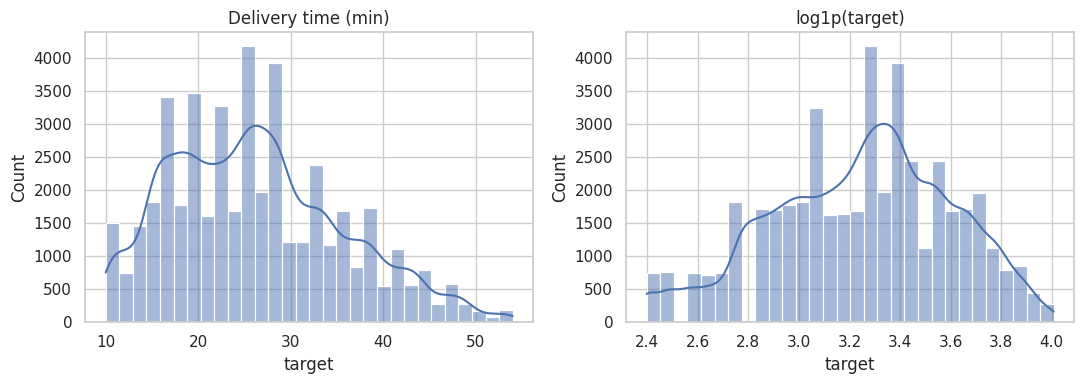


=== 2. NUMERIC vs TARGET (Spearman) ===
multiple_deliveries        0.339
distance_km                0.320
Delivery_person_Age        0.312
Delivery_person_Ratings   -0.294
Vehicle_condition         -0.222
order_hour                 0.101
pickup_wait_min           -0.007
dow                        0.007


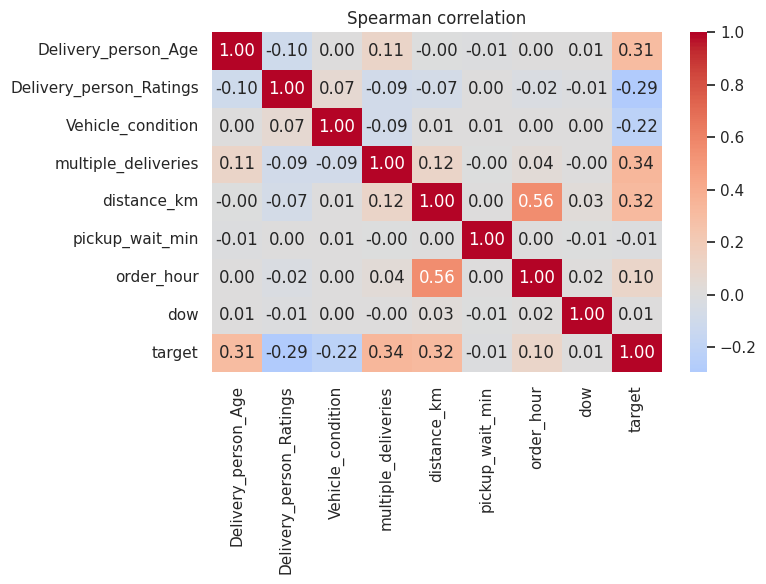


=== 3. DISTANCE ===
count    45593.00
mean         9.74
std          5.61
min          1.47
50%          9.22
90%         19.09
99%         20.56
max         20.97
coords_missing vs not, distance mean: {0: 9.72, 1: 9.91}


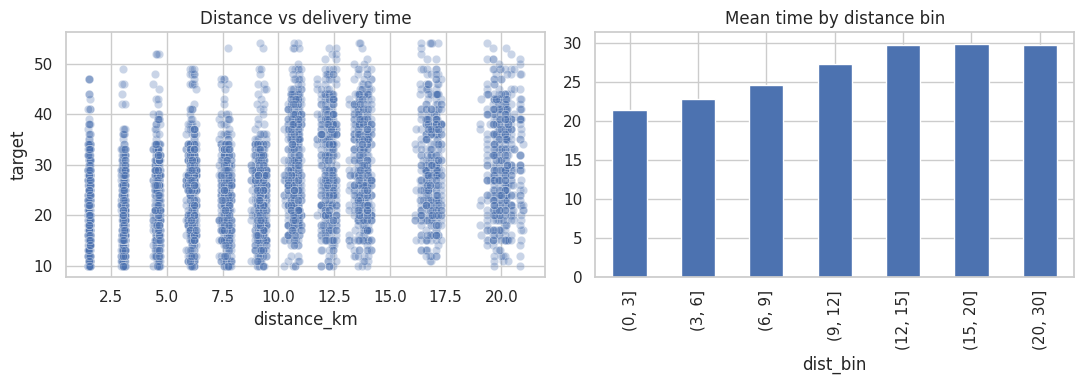


=== 4. CATEGORICAL vs TARGET (mean, count) ===

-- Weatherconditions --
                    mean  count
Weatherconditions              
Cloudy             28.92   7536
Fog                28.92   7654
NaN                26.55    616
Windy              26.12   7422
Sandstorms         25.88   7495
Stormy             25.87   7586
Sunny              21.86   7284

-- Road_traffic_density --
                       mean  count
Road_traffic_density              
Jam                   31.18  14143
High                  27.24   4425
Medium                26.70  10947
NaN                   26.54    601
Low                   21.27  15477

-- Type_of_order --
                mean  count
Type_of_order              
Meal           26.42  11458
Snack          26.29  11533
Buffet         26.28  11280
Drinks         26.19  11322

-- Type_of_vehicle --
                   mean  count
Type_of_vehicle               
motorcycle        27.61  26435
bicycle           26.43     68
scooter           24.48  15276

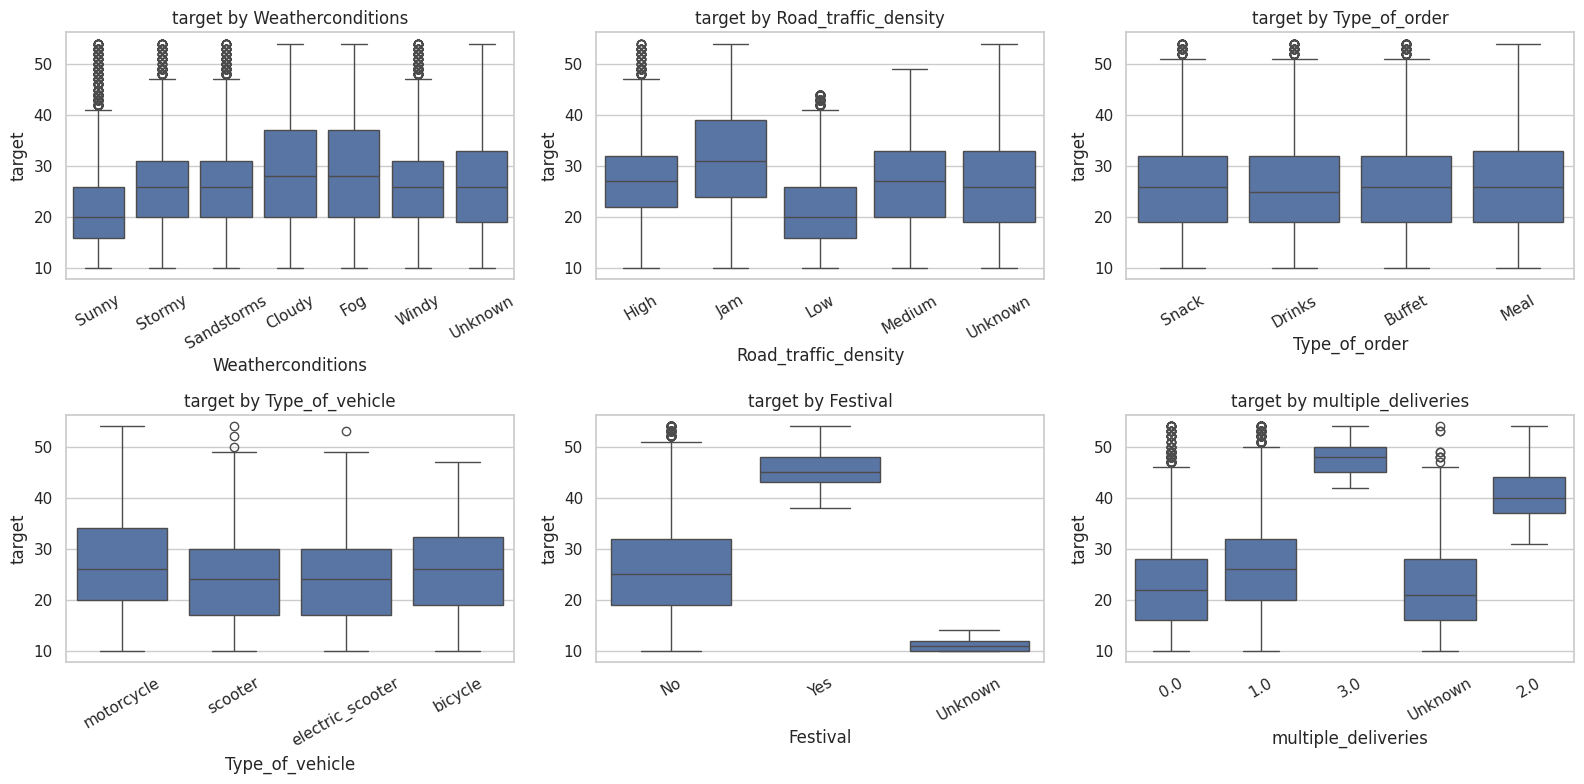


=== 5. TIME PATTERNS ===
             mean  count
order_hour              
0.0         22.17    430
8.0         19.58   1818
9.0         19.54   1947
10.0        19.48   1991
11.0        26.38   1962
12.0        26.83    892
13.0        27.54    784
14.0        27.54    791
15.0        23.19    873
16.0        22.94    709
17.0        27.41   4278
18.0        27.27   4480
19.0        30.82   4595
20.0        31.19   4539
21.0        31.09   4686
22.0        23.20   4576
23.0        22.45   4511

Day of week: {0: 26.25, 1: 25.32, 2: 27.76, 3: 25.18, 4: 26.82, 5: 26.1, 6: 26.4}


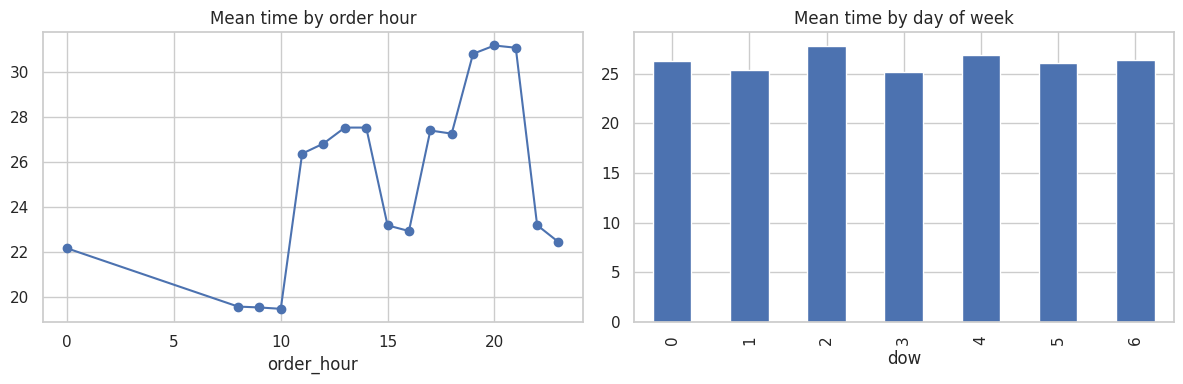


=== 6. TRAFFIC x WEATHER (mean target) ===
Weatherconditions     Cloudy   Fog  Sandstorms  Stormy  Sunny  Windy
Road_traffic_density                                                
High                    28.9  28.4        27.7    27.8   23.4   27.0
Jam                     36.7  36.8        30.0    29.9   23.1   30.2
Low                     22.2  22.3        20.3    20.7   21.4   20.7
Medium                  28.5  28.0        27.7    27.7   20.2   27.9


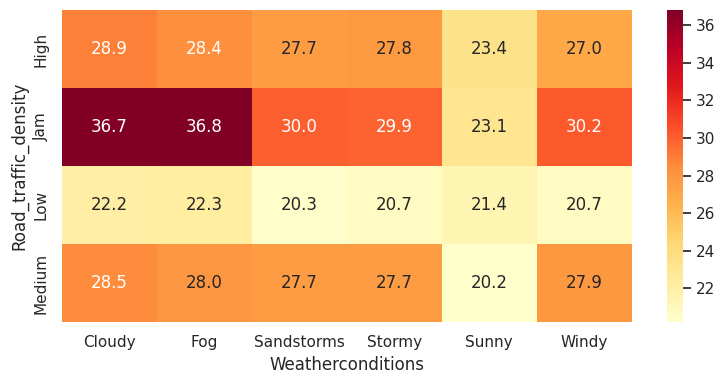


=== 7. RIDER ===
age_bin
(17, 25]    22.97
(25, 30]    24.28
(30, 35]    29.65
(35, 40]    29.48
(40, 50]    23.94
rating_bin
(0.0, 3.5]    36.04
(3.5, 4.0]    35.88
(4.0, 4.5]    30.56
(4.5, 4.8]    24.25
(4.8, 5.0]    24.63


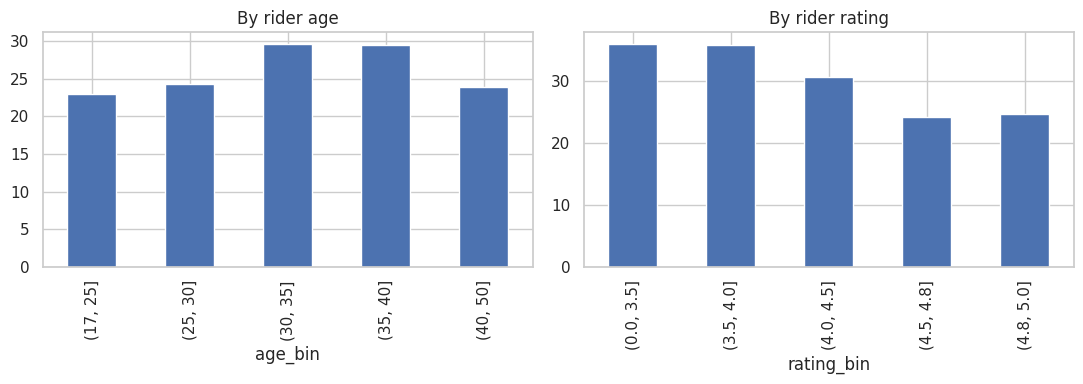


=== 8. MISSING vs TARGET ===
  Delivery_person_Age        missing=26.46 | present=26.29 | n_missing=1892
  Delivery_person_Ratings    missing=26.36 | present=26.29 | n_missing=1961
  Weatherconditions          missing=26.55 | present=26.29 | n_missing=616
  Road_traffic_density       missing=26.54 | present=26.29 | n_missing=601
  multiple_deliveries        missing=22.77 | present=26.37 | n_missing=993
  Festival                   missing=11.17 | present=26.37 | n_missing=228
  City                       missing=22.06 | present=26.41 | n_missing=1200
  order_min                  missing=26.31 | present=26.29 | n_missing=1731
  pickup_wait_min            missing=26.31 | present=26.29 | n_missing=1731
  order_hour                 missing=26.31 | present=26.29 | n_missing=1731
  age_bin                    missing=26.46 | present=26.29 | n_missing=1892
  rating_bin                 missing=26.36 | present=26.29 | n_missing=1961
coords_missing flag:  {0: 26.31, 1: 26.1}

=== 9. LONG DELIVER

In [7]:
# ===== STEP 6: EDA (STANDALONE, data modify pannala) =====
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
warnings.filterwarnings("ignore")

BASE = "/content/eta_project"
CLEAN_PATH = f"{BASE}/data/clean.csv"
FIG = f"{BASE}/reports/figures"
os.makedirs(FIG, exist_ok=True)
pd.set_option("display.max_columns", 40, "display.width", 250)
sns.set_theme(style="whitegrid")

df = pd.read_csv(CLEAN_PATH, parse_dates=["Order_Date"])
print("Shape:", df.shape)
report = {}

def save(name):
    plt.tight_layout()
    plt.savefig(f"{FIG}/{name}.png", dpi=110)
    plt.show()

# ---- Helper: haversine distance (EDA-ku mattum) ----
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.Restaurant_latitude, df.Restaurant_longitude,
                              df.Delivery_location_latitude, df.Delivery_location_longitude)
df["order_hour"] = (df.order_min // 60)
df["dow"] = df.Order_Date.dt.dayofweek
df["is_weekend"] = (df.dow >= 5).astype(int)

# ---- 1. Target ----
print("\n=== 1. TARGET ===")
print(df.target.describe().round(2).to_string())
print("Skew:", round(df.target.skew(), 3))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(df.target, bins=30, kde=True, ax=ax[0]); ax[0].set_title("Delivery time (min)")
sns.histplot(np.log1p(df.target), bins=30, kde=True, ax=ax[1]); ax[1].set_title("log1p(target)")
save("01_target")

# ---- 2. Numeric features vs target ----
print("\n=== 2. NUMERIC vs TARGET (Spearman) ===")
num = ["Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition",
       "multiple_deliveries", "distance_km", "pickup_wait_min", "order_hour", "dow"]
corr = df[num + ["target"]].corr(method="spearman")["target"].drop("target").sort_values(key=abs, ascending=False)
print(corr.round(3).to_string())
report["spearman_with_target"] = corr.round(3).to_dict()
plt.figure(figsize=(8, 6))
sns.heatmap(df[num + ["target"]].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlation")
save("02_corr")

# ---- 3. Distance ----
print("\n=== 3. DISTANCE ===")
print(df.distance_km.describe(percentiles=[.5, .9, .99]).round(2).to_string())
print("coords_missing vs not, distance mean:",
      df.groupby("coords_missing").distance_km.mean().round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df.sample(5000, random_state=0), x="distance_km", y="target", alpha=.3, ax=ax[0])
ax[0].set_title("Distance vs delivery time")
df["dist_bin"] = pd.cut(df.distance_km, [0, 3, 6, 9, 12, 15, 20, 30])
df.groupby("dist_bin").target.mean().plot(kind="bar", ax=ax[1], title="Mean time by distance bin")
save("03_distance")

# ---- 4. Categorical vs target ----
print("\n=== 4. CATEGORICAL vs TARGET (mean, count) ===")
cats = ["Weatherconditions", "Road_traffic_density", "Type_of_order", "Type_of_vehicle",
        "Festival", "City", "rider_city_code", "multiple_deliveries", "Vehicle_condition", "is_weekend"]
for c in cats:
    g = df.groupby(c, dropna=False).target.agg(["mean", "count"]).round(2).sort_values("mean", ascending=False)
    print(f"\n-- {c} --")
    print(g.head(8).to_string())
fig, axes = plt.subplots(2, 3, figsize=(16, 8))
for ax, c in zip(axes.ravel(), ["Weatherconditions", "Road_traffic_density", "Type_of_order",
                                "Type_of_vehicle", "Festival", "multiple_deliveries"]):
    sns.boxplot(data=df.fillna({c: "Unknown"}), x=c, y="target", ax=ax)
    ax.set_title(f"target by {c}"); ax.tick_params(axis="x", rotation=30)
save("04_categoricals")

# ---- 5. Time patterns ----
print("\n=== 5. TIME PATTERNS ===")
hr = df.groupby("order_hour").target.agg(["mean", "count"]).round(2)
print(hr.to_string())
print("\nDay of week:", df.groupby("dow").target.mean().round(2).to_dict())
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
hr["mean"].plot(marker="o", ax=ax[0], title="Mean time by order hour")
df.groupby("dow").target.mean().plot(kind="bar", ax=ax[1], title="Mean time by day of week")
save("05_time")

# ---- 6. Traffic x Weather interaction ----
print("\n=== 6. TRAFFIC x WEATHER (mean target) ===")
pt = df.pivot_table(index="Road_traffic_density", columns="Weatherconditions", values="target", aggfunc="mean").round(1)
print(pt.to_string())
plt.figure(figsize=(8, 4))
sns.heatmap(pt, annot=True, fmt=".1f", cmap="YlOrRd")
save("06_traffic_weather")

# ---- 7. Rider age / rating ----
print("\n=== 7. RIDER ===")
df["age_bin"] = pd.cut(df.Delivery_person_Age, [17, 25, 30, 35, 40, 50])
df["rating_bin"] = pd.cut(df.Delivery_person_Ratings, [0, 3.5, 4.0, 4.5, 4.8, 5.0])
print(df.groupby("age_bin").target.mean().round(2).to_string())
print(df.groupby("rating_bin").target.mean().round(2).to_string())
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
df.groupby("age_bin").target.mean().plot(kind="bar", ax=ax[0], title="By rider age")
df.groupby("rating_bin").target.mean().plot(kind="bar", ax=ax[1], title="By rider rating")
save("07_rider")

# ---- 8. Missingness vs target (informative missing) ----
print("\n=== 8. MISSING vs TARGET ===")
for c in [c for c in df.columns if df[c].isna().any() and c not in ("target",)]:
    m = df[c].isna()
    print(f"  {c:26s} missing={df.loc[m,'target'].mean():.2f} | present={df.loc[~m,'target'].mean():.2f} | n_missing={int(m.sum())}")
print("coords_missing flag: ", df.groupby("coords_missing").target.mean().round(2).to_dict())

# ---- 9. Long deliveries ----
print("\n=== 9. LONG DELIVERIES (target >= 45) ===")
long_ = df[df.target >= 45]
print("Count:", len(long_), f"({len(long_)/len(df)*100:.1f}%)")
for c in ["Road_traffic_density", "Weatherconditions", "Festival", "multiple_deliveries"]:
    print(f"  {c}:", long_[c].value_counts(normalize=True).round(2).head(4).to_dict())

# ---- 10. Date range ----
print("\n=== 10. DATE RANGE ===")
print(df.Order_Date.min().date(), "->", df.Order_Date.max().date(), "| days:", df.Order_Date.nunique())
print("Rows per day (min/mean/max):", df.groupby("Order_Date").size().agg(["min", "mean", "max"]).round(0).to_dict())

with open(f"{BASE}/reports/eda_summary.json", "w") as f:
    json.dump(report, f, indent=2)
print("\nSaved figures:", FIG)
print("STEP 6 DONE")

In [8]:
# ===== STEP 7: Feature engineering + time-based split (STANDALONE) =====
import os, json
import numpy as np, pandas as pd

BASE = "/content/eta_project"
CLEAN_PATH = f"{BASE}/data/clean.csv"
OUT = f"{BASE}/data/splits"          # raw train.csv-oda mix aagakoodadhu
os.makedirs(OUT, exist_ok=True)
os.makedirs(f"{BASE}/reports", exist_ok=True)
pd.set_option("display.max_columns", 50, "display.width", 250)

df = pd.read_csv(CLEAN_PATH, parse_dates=["Order_Date"])
n0 = len(df)

# ---- 1. Distance ----
def haversine(lat1, lon1, lat2, lon2):
    R = 6371
    p1, p2 = np.radians(lat1), np.radians(lat2)
    a = np.sin((p2 - p1) / 2) ** 2 + np.cos(p1) * np.cos(p2) * np.sin(np.radians(lon2 - lon1) / 2) ** 2
    return 2 * R * np.arcsin(np.sqrt(a))

df["distance_km"] = haversine(df.Restaurant_latitude, df.Restaurant_longitude,
                              df.Delivery_location_latitude, df.Delivery_location_longitude)

# ---- 2. Time features (order time mattum, pickup time use pannala = leakage) ----
h = df.order_min // 60
df["order_hour"] = h
df["daypart"] = np.select(
    [h.isna(), (h <= 7) | (h >= 22), h.between(8, 10), h.between(11, 14),
     h.between(15, 16), h.between(17, 18), h.between(19, 21)],
    ["Unknown", "late_night", "morning", "midday", "afternoon", "early_evening", "peak_night"],
    default="Unknown")
df["is_peak"] = h.between(19, 21).astype(int)
df["is_weekend"] = (df.Order_Date.dt.dayofweek >= 5).astype(int)

# ---- 3. Ordinal / flag features (missing-ku munnadiye) ----
df["traffic_ord"] = df.Road_traffic_density.map({"Low": 0, "Medium": 1, "High": 2, "Jam": 3})
df["festival_flag"] = (df.Festival == "Yes").astype(int)

# ---- 4. Missing flags ----
df["rider_info_missing"] = (df.Delivery_person_Age.isna() | df.Delivery_person_Ratings.isna()).astype(int)
df["order_time_missing"] = df.order_min.isna().astype(int)
df["festival_missing"] = df.Festival.isna().astype(int)
df["city_missing"] = df.City.isna().astype(int)
df["multi_missing"] = df.multiple_deliveries.isna().astype(int)
df["weather_traffic_missing"] = (df.Weatherconditions.isna() | df.Road_traffic_density.isna()).astype(int)

# ---- 5. Categorical: missing -> "Unknown" ----
for c in ["Weatherconditions", "Road_traffic_density", "Festival", "City", "Type_of_vehicle"]:
    df[c] = df[c].fillna("Unknown")
df["weather_traffic"] = df.Weatherconditions + "_" + df.Road_traffic_density

# ---- 6. Time-based split (30 / 7 / 7 days) ----
dates = np.sort(df.Order_Date.unique())
train_d, val_d, test_d = dates[:30], dates[30:37], dates[37:]
df["split"] = np.where(df.Order_Date.isin(train_d), "train",
               np.where(df.Order_Date.isin(val_d), "val", "test"))
assert max(train_d) < min(val_d) and max(val_d) < min(test_d), "Date overlap!"

# ---- 7. Feature config ----
NUM = ["Delivery_person_Age", "Delivery_person_Ratings", "Vehicle_condition", "multiple_deliveries",
       "distance_km", "order_min", "order_hour", "traffic_ord", "festival_flag", "is_peak",
       "is_weekend", "coords_missing", "rider_info_missing", "order_time_missing",
       "festival_missing", "city_missing", "multi_missing", "weather_traffic_missing"]
CAT = ["Weatherconditions", "Road_traffic_density", "Festival", "City",
       "Type_of_vehicle", "daypart", "weather_traffic"]
DROPPED = {
    "ID": "identifier",
    "Delivery_person_ID": "not a reliable rider identity (audit)",
    "pick_min": "leakage: order time-la theriyadhu",
    "pickup_wait_min": "leakage + no signal",
    "rider_city_code": "no signal in EDA (26-27 min everywhere)",
    "Type_of_order": "no signal in EDA",
    "raw lat/long": "distance_km already captures it; Step 8-la test pannalaam",
}
cfg = {"num": NUM, "cat": CAT, "target": "target", "dropped": DROPPED,
       "split_dates": {"train": [str(pd.Timestamp(train_d[0]).date()), str(pd.Timestamp(train_d[-1]).date())],
                       "val": [str(pd.Timestamp(val_d[0]).date()), str(pd.Timestamp(val_d[-1]).date())],
                       "test": [str(pd.Timestamp(test_d[0]).date()), str(pd.Timestamp(test_d[-1]).date())]}}

keep = NUM + CAT + ["target", "Order_Date"]
for s in ["train", "val", "test"]:
    df.loc[df.split == s, keep].to_csv(f"{OUT}/{s}_fe.csv", index=False)
with open(f"{BASE}/data/feature_config.json", "w") as f:
    json.dump(cfg, f, indent=2)

# ---- 8. Checks ----
print("Rows:", n0, "->", len(df))
print("\n=== SPLIT SUMMARY ===")
summ = df.groupby("split").agg(rows=("target", "size"), start=("Order_Date", "min"), end=("Order_Date", "max"),
                               days=("Order_Date", "nunique"), target_mean=("target", "mean"),
                               target_std=("target", "std")).round(2)
summ["pct"] = (summ.rows / len(df) * 100).round(1)
print(summ.loc[["train", "val", "test"]].to_string())

print("\n=== DRIFT CHECK (split-wise mean) ===")
chk = df.groupby("split")[["distance_km", "multiple_deliveries", "traffic_ord", "festival_flag", "is_peak"]].mean().round(3)
print(chk.loc[["train", "val", "test"]].to_string())

print("\n=== MISSING (train, features) ===")
tr = df[df.split == "train"]
m = tr[NUM + CAT].isna().sum()
print(m[m > 0].sort_values(ascending=False).to_string())

print("\nNew categories (val/test-la irukku, train-la illa):")
for c in CAT:
    new = set(df[df.split != "train"][c].unique()) - set(tr[c].unique())
    if new: print(f"  {c}: {new}")

print("\nFeatures:", len(NUM), "numeric +", len(CAT), "categorical")
print("\nHEAD:")
print(df[keep].head(3).T)
print("\nSaved:", OUT)
print("STEP 7 DONE")

Rows: 45593 -> 45593

=== SPLIT SUMMARY ===
        rows      start        end  days  target_mean  target_std   pct
split                                                                  
train  30739 2022-02-11 2022-03-23    30        26.37        9.38  67.4
val     7525 2022-03-24 2022-03-30     7        25.74        9.34  16.5
test    7329 2022-03-31 2022-04-06     7        26.53        9.42  16.1

=== DRIFT CHECK (split-wise mean) ===
       distance_km  multiple_deliveries  traffic_ord  festival_flag  is_peak
split                                                                       
train        9.757                0.747        1.384          0.020    0.304
val          9.037                0.734        1.372          0.018    0.294
test        10.361                0.745        1.392          0.020    0.308

=== MISSING (train, features) ===
Delivery_person_Ratings    1343
Delivery_person_Age        1267
order_min                  1184
order_hour                 1184
multiple_

In [10]:
# ===== STEP 8: Baselines (STANDALONE) =====
import json, time, warnings
import numpy as np, pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
warnings.filterwarnings("ignore")

BASE = "/content/eta_project"
SPL = f"{BASE}/data/splits"
pd.set_option("display.max_columns", 40, "display.width", 250)

cfg = json.load(open(f"{BASE}/data/feature_config.json"))
NUM, CAT, TGT = cfg["num"], cfg["cat"], cfg["target"]
tr = pd.read_csv(f"{SPL}/train_fe.csv")
va = pd.read_csv(f"{SPL}/val_fe.csv")   # test touch pannala
print("Train:", tr.shape, "| Val:", va.shape)

def make_pre(num_cols, cat_cols, scale):
    num_steps = [("imp", SimpleImputer(strategy="median"))]
    if scale:
        num_steps.append(("sc", StandardScaler()))
    return ColumnTransformer([
        ("num", Pipeline(num_steps), num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat_cols),
    ])

def evaluate(name, model, num_cols, cat_cols, scale):
    pipe = Pipeline([("pre", make_pre(num_cols, cat_cols, scale)), ("m", model)])
    t0 = time.time()
    pipe.fit(tr[num_cols + cat_cols], tr[TGT])
    p_tr = pipe.predict(tr[num_cols + cat_cols])
    p_va = pipe.predict(va[num_cols + cat_cols])
    res = {
        "model": name,
        "train_MAE": mean_absolute_error(tr[TGT], p_tr),
        "val_MAE": mean_absolute_error(va[TGT], p_va),
        "val_RMSE": mean_squared_error(va[TGT], p_va) ** 0.5,
        "val_R2": r2_score(va[TGT], p_va),
        "sec": time.time() - t0,
    }
    return res, pipe, p_va

results, preds = [], {}
models = [
    ("Mean baseline",     DummyRegressor(strategy="mean"), True),
    ("Linear Regression", LinearRegression(), True),
    ("Ridge (alpha=10)",  Ridge(alpha=10), True),
    ("Random Forest",     RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                                n_jobs=-1, random_state=42), False),
]
fitted = {}
for name, m, sc in models:
    r, pipe, p = evaluate(name, m, NUM, CAT, sc)
    results.append(r); preds[name] = p; fitted[name] = pipe
    print(f"{name:20s} train_MAE={r['train_MAE']:.3f} | val_MAE={r['val_MAE']:.3f} | "
          f"val_RMSE={r['val_RMSE']:.3f} | R2={r['val_R2']:.3f} | {r['sec']:.1f}s")

# ---- Ablation: rider Age/Ratings illama RF ----
RIDER = ["Delivery_person_Age", "Delivery_person_Ratings", "rider_info_missing"]
num_noR = [c for c in NUM if c not in RIDER]
r, _, _ = evaluate("RF without rider features",
                   RandomForestRegressor(n_estimators=300, min_samples_leaf=3, max_features=0.5,
                                         n_jobs=-1, random_state=42), num_noR, CAT, False)
results.append(r)
print(f"\nAblation -> {r['model']}: val_MAE={r['val_MAE']:.3f} | RMSE={r['val_RMSE']:.3f}")

res_df = pd.DataFrame(results).round(3)
print("\n=== SUMMARY (val) ===")
print(res_df.to_string(index=False))
res_df.to_csv(f"{BASE}/reports/baseline_results.csv", index=False)

# ---- RF feature importance ----
rf = fitted["Random Forest"]
names = rf.named_steps["pre"].get_feature_names_out()
imp = pd.Series(rf.named_steps["m"].feature_importances_, index=names).sort_values(ascending=False)
print("\n=== RF TOP 15 FEATURE IMPORTANCE ===")
print(imp.head(15).round(4).to_string())

# ---- Error analysis (RF, val) ----
v = va.copy()
v["pred"] = preds["Random Forest"]
v["abs_err"] = (v[TGT] - v["pred"]).abs()
v["err"] = v["pred"] - v[TGT]
print("\n=== RF ERROR ANALYSIS (val) ===")
for c in ["Road_traffic_density", "multiple_deliveries", "Festival", "daypart", "City"]:
    g = v.groupby(c, dropna=False).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("err", "mean")).round(2)
    print(f"\n-- {c} --")
    print(g.to_string())
print("\nTarget >= 45 rows: MAE =", round(v[v[TGT] >= 45].abs_err.mean(), 2),
      "| bias =", round(v[v[TGT] >= 45].err.mean(), 2))
print("Within +-5 min:", round((v.abs_err <= 5).mean() * 100, 1), "% | within +-10 min:",
      round((v.abs_err <= 10).mean() * 100, 1), "%")
print("\nSTEP 8 DONE")

Train: (30739, 27) | Val: (7525, 27)
Mean baseline        train_MAE=7.600 | val_MAE=7.601 | val_RMSE=9.359 | R2=-0.005 | 0.5s
Linear Regression    train_MAE=4.570 | val_MAE=4.608 | val_RMSE=5.814 | R2=0.612 | 0.9s
Ridge (alpha=10)     train_MAE=4.571 | val_MAE=4.609 | val_RMSE=5.813 | R2=0.612 | 0.4s
Random Forest        train_MAE=1.994 | val_MAE=3.086 | val_RMSE=3.887 | R2=0.827 | 51.9s

Ablation -> RF without rider features: val_MAE=4.412 | RMSE=5.620

=== SUMMARY (val) ===
                    model  train_MAE  val_MAE  val_RMSE  val_R2    sec
            Mean baseline      7.600    7.601     9.359  -0.005  0.488
        Linear Regression      4.570    4.608     5.814   0.612  0.929
         Ridge (alpha=10)      4.571    4.609     5.813   0.612  0.414
            Random Forest      1.994    3.086     3.887   0.827 51.853
RF without rider features      3.081    4.412     5.620   0.638 33.714

=== RF TOP 15 FEATURE IMPORTANCE ===
num__Delivery_person_Ratings          0.1798
num__dista

In [11]:
# ===== STEP 9: Gradient boosting (STANDALONE) =====
import json, time, warnings, subprocess, sys
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
try:
    import catboost
except ImportError:
    subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", "catboost"])
    import catboost
import lightgbm as lgb
import xgboost as xgb
from catboost import CatBoostRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

BASE = "/content/eta_project"
SPL = f"{BASE}/data/splits"
pd.set_option("display.max_columns", 40, "display.width", 250)

cfg = json.load(open(f"{BASE}/data/feature_config.json"))
NUM, CAT, TGT = cfg["num"], cfg["cat"], cfg["target"]
tr = pd.read_csv(f"{SPL}/train_fe.csv")
va = pd.read_csv(f"{SPL}/val_fe.csv")   # test touch pannala
print("Train:", tr.shape, "| Val:", va.shape)
ytr, yva = tr[TGT], va[TGT]

# ---- Data prep: category dtype (train categories) ----
def prep_cat(d):
    X = d[NUM + CAT].copy()
    for c in CAT:
        X[c] = X[c].astype(pd.CategoricalDtype(sorted(tr[c].astype(str).unique())))
    return X
Xtr, Xva = prep_cat(tr), prep_cat(va)

def prep_cb(d):                      # CatBoost-ku cat columns string
    X = d[NUM + CAT].copy()
    for c in CAT:
        X[c] = X[c].astype(str)
    return X
Xtr_cb, Xva_cb = prep_cb(tr), prep_cb(va)

results, preds, best_iters, fitted = [], {}, {}, {}

def log_result(name, p, iters, sec):
    r = {"model": name,
         "val_MAE": mean_absolute_error(yva, p),
         "val_RMSE": mean_squared_error(yva, p) ** 0.5,
         "val_R2": r2_score(yva, p),
         "best_iter": iters, "sec": sec}
    results.append(r); preds[name] = p; best_iters[name] = iters
    print(f"{name:14s} val_MAE={r['val_MAE']:.3f} | RMSE={r['val_RMSE']:.3f} | "
          f"R2={r['val_R2']:.3f} | iters={iters} | {sec:.1f}s")

# ---- 1. LightGBM (L2 and L1) ----
for nm, obj in [("LGBM_L2", "regression"), ("LGBM_L1", "regression_l1")]:
    t0 = time.time()
    m = lgb.LGBMRegressor(objective=obj, n_estimators=3000, learning_rate=0.03, num_leaves=31,
                          min_child_samples=20, subsample=0.8, subsample_freq=1,
                          colsample_bytree=0.8, random_state=42, verbose=-1)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)], eval_metric="l1",
          callbacks=[lgb.early_stopping(100, verbose=False)])
    fitted[nm] = m
    log_result(nm, m.predict(Xva), int(m.best_iteration_), time.time() - t0)

# ---- 2. XGBoost ----
t0 = time.time()
m = xgb.XGBRegressor(n_estimators=3000, learning_rate=0.03, max_depth=6, min_child_weight=3,
                     subsample=0.8, colsample_bytree=0.8, tree_method="hist",
                     enable_categorical=True, eval_metric="mae",
                     early_stopping_rounds=100, random_state=42)
m.fit(Xtr, ytr, eval_set=[(Xva, yva)], verbose=False)
fitted["XGB"] = m
log_result("XGB", m.predict(Xva), int(m.best_iteration), time.time() - t0)

# ---- 3. CatBoost ----
t0 = time.time()
m = CatBoostRegressor(iterations=3000, learning_rate=0.05, depth=6, loss_function="RMSE",
                      eval_metric="MAE", random_seed=42, verbose=0,
                      early_stopping_rounds=100, cat_features=CAT)
m.fit(Xtr_cb, ytr, eval_set=(Xva_cb, yva))
fitted["CatBoost"] = m
log_result("CatBoost", m.predict(Xva_cb), int(m.get_best_iteration()), time.time() - t0)

# ---- 4. Simple blend (average of 4) ----
blend = np.mean([preds[k] for k in ["LGBM_L2", "LGBM_L1", "XGB", "CatBoost"]], axis=0)
log_result("Blend_avg", blend, 0, 0.0)

# ---- Summary + compare with Step 8 baselines ----
res_df = pd.DataFrame(results).round(3)
print("\n=== SUMMARY (val) ===")
print(res_df.sort_values("val_MAE").to_string(index=False))
try:
    base = pd.read_csv(f"{BASE}/reports/baseline_results.csv")[["model", "val_MAE", "val_RMSE", "val_R2"]]
    print("\n=== STEP 8 BASELINES (reference) ===")
    print(base.to_string(index=False))
except Exception as e:
    print("baseline_results.csv read aagala:", e)
res_df.to_csv(f"{BASE}/reports/boosting_results.csv", index=False)
json.dump(best_iters, open(f"{BASE}/reports/best_iters.json", "w"), indent=2)

# ---- Feature importance (LightGBM L2, gain) ----
lm = fitted["LGBM_L2"]
imp = pd.Series(lm.booster_.feature_importance(importance_type="gain"),
                index=lm.booster_.feature_name()).sort_values(ascending=False)
print("\n=== LGBM TOP 15 (gain, % of total) ===")
print((imp / imp.sum() * 100).head(15).round(2).to_string())

# ---- Error analysis (best single model) ----
singles = res_df[res_df.model != "Blend_avg"].sort_values("val_MAE")
best = singles.iloc[0].model
print("\nBest single model:", best)
v = va.copy()
v["pred"] = preds[best]
v["abs_err"] = (v[TGT] - v["pred"]).abs()
v["err"] = v["pred"] - v[TGT]
for c in ["Road_traffic_density", "daypart", "multiple_deliveries"]:
    g = v.groupby(c, dropna=False).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"), bias=("err", "mean")).round(2)
    print(f"\n-- {c} --")
    print(g.to_string())
lg = v[v[TGT] >= 45]
print("\nTarget >= 45: n =", len(lg), "| MAE =", round(lg.abs_err.mean(), 2), "| bias =", round(lg.err.mean(), 2))
print("Within +-5 min:", round((v.abs_err <= 5).mean() * 100, 1), "% | +-10 min:",
      round((v.abs_err <= 10).mean() * 100, 1), "%")

# ---- Save val predictions ----
out = va[[TGT]].copy()
for k, p in preds.items():
    out[k] = p
out.to_csv(f"{BASE}/reports/val_predictions.csv", index=False)
print("\nSTEP 9 DONE")

Train: (30739, 27) | Val: (7525, 27)
LGBM_L2        val_MAE=3.021 | RMSE=3.797 | R2=0.835 | iters=343 | 11.6s
LGBM_L1        val_MAE=3.045 | RMSE=3.876 | R2=0.828 | iters=554 | 10.8s
XGB            val_MAE=3.009 | RMSE=3.788 | R2=0.835 | iters=456 | 9.5s
CatBoost       val_MAE=3.034 | RMSE=3.822 | R2=0.832 | iters=1345 | 72.7s
Blend_avg      val_MAE=3.010 | RMSE=3.796 | R2=0.835 | iters=0 | 0.0s

=== SUMMARY (val) ===
    model  val_MAE  val_RMSE  val_R2  best_iter    sec
      XGB    3.009     3.788   0.835        456  9.470
Blend_avg    3.010     3.796   0.835          0  0.000
  LGBM_L2    3.021     3.797   0.835        343 11.619
 CatBoost    3.034     3.822   0.832       1345 72.669
  LGBM_L1    3.045     3.876   0.828        554 10.803

=== STEP 8 BASELINES (reference) ===
                    model  val_MAE  val_RMSE  val_R2
            Mean baseline    7.601     9.359  -0.005
        Linear Regression    4.608     5.814   0.612
         Ridge (alpha=10)    4.609     5.813   0.61

Train: (30739, 27) | Val: (7525, 27) | Test: (7329, 27)
Unseen test categories (NaN aagum): none

Tuning done: 130s | best val_MAE = 3.016 | best_iter = 330
Best params: {'objective': 'regression', 'num_leaves': 29, 'min_child_samples': 79, 'subsample': 0.9246, 'colsample_bytree': 0.9911, 'reg_lambda': 0.3232, 'reg_alpha': 5.6355}

Train-only tuned model -> val MAE 3.047 | TEST MAE 3.126

=== FINAL TEST RESULTS ===
                                   MAE   RMSE     R2  within5  within10
Mean baseline                    7.596  9.421 -0.001   38.450    68.863
Tuned LGBM (train only)          3.126  3.901  0.828   81.307    98.813
FINAL LGBM (train+val, 3 seeds)  3.117  3.888  0.830   81.580    98.786

=== TEST ERROR ANALYSIS ===

-- Road_traffic_density --
                         n   MAE  bias
Road_traffic_density                  
High                   656  3.46 -0.06
Jam                   2309  3.50  0.08
Low                   2439  2.60  0.01
Medium                1826  3.04  0.10
Un

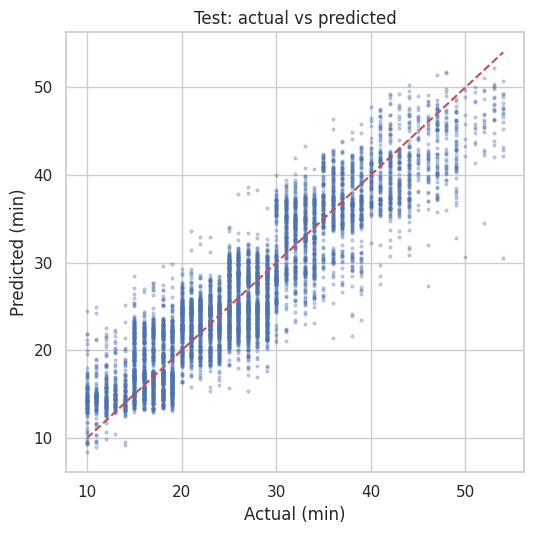


=== SHAP (test sample 2000) ===
weather_traffic            25.09
Delivery_person_Age        17.52
distance_km                14.71
Vehicle_condition          13.07
Delivery_person_Ratings    12.24
Weatherconditions           5.71
multiple_deliveries         4.09
City                        2.32
festival_flag               1.60
order_min                   0.93
traffic_ord                 0.83
city_missing                0.54
Type_of_vehicle             0.34
is_weekend                  0.28
festival_missing            0.26


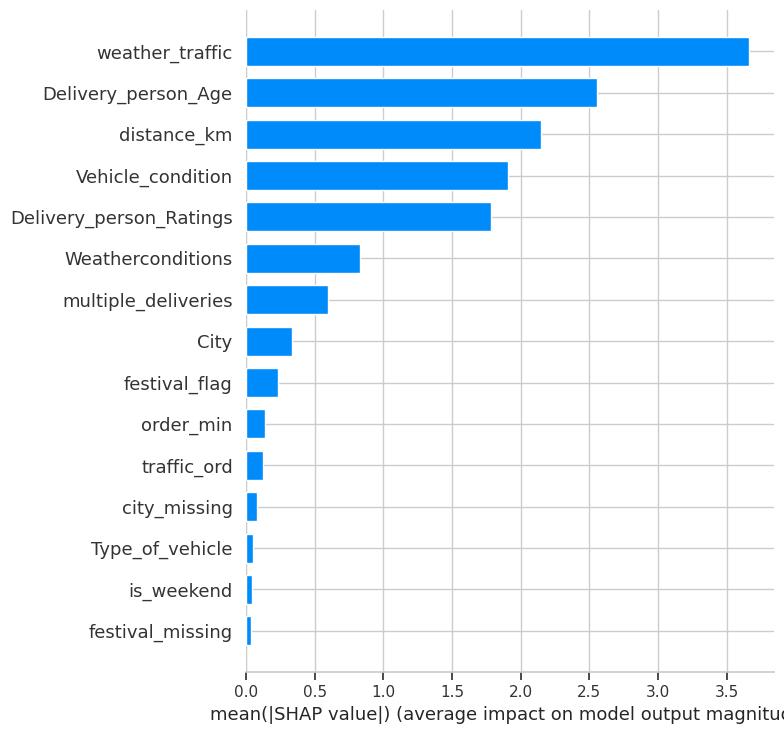

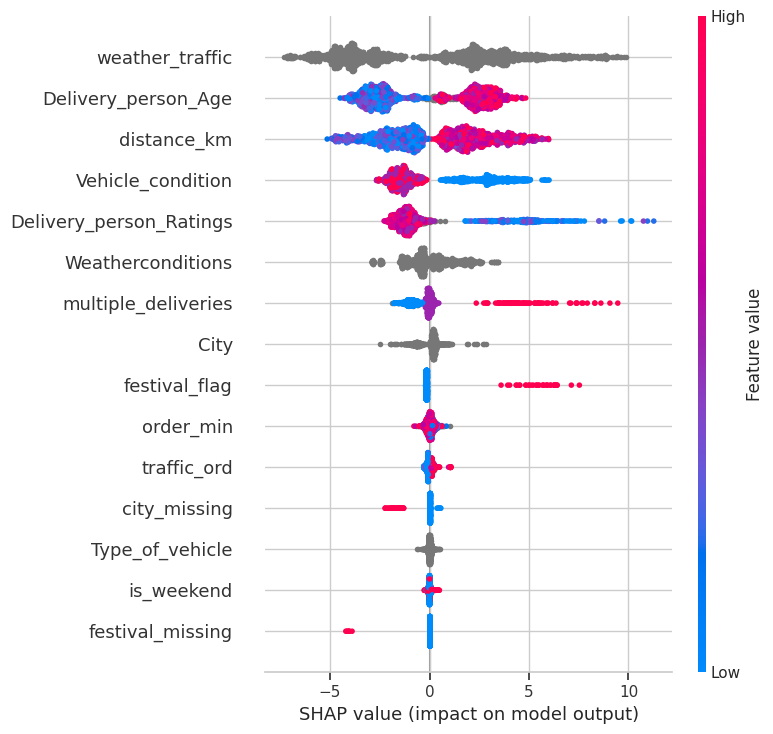


Saved: models/eta_lgbm_final.joblib, models/final_meta.json
STEP 10 DONE


In [12]:
# ===== STEP 10: Tuning + Final TEST + SHAP (STANDALONE) =====
import os, json, time, warnings, subprocess, sys
import numpy as np, pandas as pd
warnings.filterwarnings("ignore")
for pkg in ["optuna", "shap"]:
    try:
        __import__(pkg)
    except ImportError:
        subprocess.check_call([sys.executable, "-m", "pip", "-q", "install", pkg])
import optuna, shap, joblib
import lightgbm as lgb
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
optuna.logging.set_verbosity(optuna.logging.WARNING)

BASE = "/content/eta_project"
SPL = f"{BASE}/data/splits"
FIG = f"{BASE}/reports/figures"
os.makedirs(FIG, exist_ok=True)
os.makedirs(f"{BASE}/models", exist_ok=True)
pd.set_option("display.max_columns", 40, "display.width", 250)

cfg = json.load(open(f"{BASE}/data/feature_config.json"))
NUM, CAT, TGT = cfg["num"], cfg["cat"], cfg["target"]
tr = pd.read_csv(f"{SPL}/train_fe.csv")
va = pd.read_csv(f"{SPL}/val_fe.csv")
te = pd.read_csv(f"{SPL}/test_fe.csv")      # final evaluation-ku mattum
print("Train:", tr.shape, "| Val:", va.shape, "| Test:", te.shape)

# ---- Category dtype: train+val categories, ellaa set-kum same ----
tv = pd.concat([tr, va], ignore_index=True)
cat_types = {c: pd.CategoricalDtype(sorted(tv[c].astype(str).unique())) for c in CAT}

def prep(d):
    X = d[NUM + CAT].copy()
    for c in CAT:
        X[c] = X[c].astype(str).astype(cat_types[c])
    return X

Xtr, Xva, Xte, Xtv = prep(tr), prep(va), prep(te), prep(tv)
ytr, yva, yte, ytv = tr[TGT], va[TGT], te[TGT], tv[TGT]
print("Unseen test categories (NaN aagum):",
      {c: int(Xte[c].isna().sum()) for c in CAT if Xte[c].isna().sum() > 0} or "none")

# ---- 1. Optuna tuning (val MAE) ----
def build(params, seed=42):
    return lgb.LGBMRegressor(**params, metric="l1", subsample_freq=1,
                             random_state=seed, verbose=-1)

def objective(trial):
    params = dict(
        objective=trial.suggest_categorical("objective", ["regression", "regression_l1"]),
        n_estimators=4000,
        learning_rate=0.03,
        num_leaves=trial.suggest_int("num_leaves", 15, 127, log=True),
        min_child_samples=trial.suggest_int("min_child_samples", 10, 80),
        subsample=trial.suggest_float("subsample", 0.6, 1.0),
        colsample_bytree=trial.suggest_float("colsample_bytree", 0.5, 1.0),
        reg_lambda=trial.suggest_float("reg_lambda", 1e-3, 30, log=True),
        reg_alpha=trial.suggest_float("reg_alpha", 1e-3, 10, log=True),
    )
    m = build(params)
    m.fit(Xtr, ytr, eval_set=[(Xva, yva)],
          callbacks=[lgb.early_stopping(100, first_metric_only=True, verbose=False)])
    trial.set_user_attr("best_iter", int(m.best_iteration_))
    return mean_absolute_error(yva, m.predict(Xva, num_iteration=m.best_iteration_))

t0 = time.time()
study = optuna.create_study(direction="minimize", sampler=optuna.samplers.TPESampler(seed=42))
study.optimize(objective, n_trials=30, timeout=900)
best = study.best_trial
best_params = dict(best.params)
best_iter = best.user_attrs["best_iter"]
print(f"\nTuning done: {time.time()-t0:.0f}s | best val_MAE = {best.value:.3f} | best_iter = {best_iter}")
print("Best params:", {k: (round(v, 4) if isinstance(v, float) else v) for k, v in best_params.items()})

# ---- 2. Train-only model (tuned) -> val residuals + test ----
params_final = dict(best_params, n_estimators=best_iter)
m_tr = build(params_final).fit(Xtr, ytr)
p_va = m_tr.predict(Xva)
p_te_tr = m_tr.predict(Xte)
res_val = yva - p_va
q10, q90 = np.quantile(res_val, [0.10, 0.90])
print(f"\nTrain-only tuned model -> val MAE {mean_absolute_error(yva, p_va):.3f} | "
      f"TEST MAE {mean_absolute_error(yte, p_te_tr):.3f}")

# ---- 3. Final: train+val refit, 3 seeds average ----
n_final = int(best_iter * 1.15)
seeds = [42, 7, 2026]
final_models = [build(dict(best_params, n_estimators=n_final), seed=s).fit(Xtv, ytv) for s in seeds]
p_te = np.mean([m.predict(Xte) for m in final_models], axis=0)

def metrics(y, p):
    e = np.abs(y - p)
    return {"MAE": mean_absolute_error(y, p), "RMSE": mean_squared_error(y, p) ** 0.5,
            "R2": r2_score(y, p), "within5": (e <= 5).mean() * 100, "within10": (e <= 10).mean() * 100}

mean_base = np.full(len(yte), ytv.mean())
rows = {"Mean baseline": metrics(yte, mean_base),
        "Tuned LGBM (train only)": metrics(yte, p_te_tr),
        "FINAL LGBM (train+val, 3 seeds)": metrics(yte, p_te)}
summary = pd.DataFrame(rows).T.round(3)
print("\n=== FINAL TEST RESULTS ===")
print(summary.to_string())
summary.to_csv(f"{BASE}/reports/final_test_results.csv")

# ---- 4. Test error analysis ----
t = te.copy()
t["pred"] = p_te
t["abs_err"] = (t[TGT] - t["pred"]).abs()
t["err"] = t["pred"] - t[TGT]
print("\n=== TEST ERROR ANALYSIS ===")
for c in ["Road_traffic_density", "daypart", "multiple_deliveries", "City"]:
    if c in t.columns:
        g = t.groupby(c, dropna=False).agg(n=("abs_err", "size"), MAE=("abs_err", "mean"),
                                           bias=("err", "mean")).round(2)
        print(f"\n-- {c} --")
        print(g.to_string())
lg = t[t[TGT] >= 45]
print(f"\nTarget >= 45: n={len(lg)} | MAE={lg.abs_err.mean():.2f} | bias={lg.err.mean():.2f}")

# ---- 5. Prediction interval (val residual q10/q90) ----
lo, hi = p_te + q10, p_te + q90
cover = ((yte >= lo) & (yte <= hi)).mean() * 100
print(f"\n80% interval: pred {q10:+.1f} / {q90:+.1f} min | test coverage = {cover:.1f}% (target ~80%)")

plt.figure(figsize=(5.5, 5.5))
plt.scatter(yte, p_te, s=4, alpha=.3)
lim = [yte.min(), yte.max()]
plt.plot(lim, lim, "r--")
plt.xlabel("Actual (min)"); plt.ylabel("Predicted (min)"); plt.title("Test: actual vs predicted")
plt.tight_layout(); plt.savefig(f"{FIG}/10_test_actual_vs_pred.png", dpi=110); plt.show()

# ---- 6. SHAP ----
print("\n=== SHAP (test sample 2000) ===")
Xs = Xte.sample(min(2000, len(Xte)), random_state=0)
explainer = shap.TreeExplainer(final_models[0])
sv = explainer.shap_values(Xs)
mean_abs = pd.Series(np.abs(sv).mean(axis=0), index=Xs.columns).sort_values(ascending=False)
print((mean_abs / mean_abs.sum() * 100).head(15).round(2).to_string())
plt.figure(); shap.summary_plot(sv, Xs, plot_type="bar", max_display=15, show=False)
plt.tight_layout(); plt.savefig(f"{FIG}/10_shap_bar.png", dpi=110); plt.show()
plt.figure(); shap.summary_plot(sv, Xs, max_display=15, show=False)
plt.tight_layout(); plt.savefig(f"{FIG}/10_shap_beeswarm.png", dpi=110); plt.show()

# ---- 7. Save ----
joblib.dump({"models": final_models, "cat_types": cat_types, "NUM": NUM, "CAT": CAT},
            f"{BASE}/models/eta_lgbm_final.joblib")
json.dump({"best_params": best_params, "best_iter": best_iter, "n_final": n_final,
           "interval_q10": float(q10), "interval_q90": float(q90),
           "test": summary.loc["FINAL LGBM (train+val, 3 seeds)"].to_dict()},
          open(f"{BASE}/models/final_meta.json", "w"), indent=2)
print("\nSaved: models/eta_lgbm_final.joblib, models/final_meta.json")
print("STEP 10 DONE")